# **Concrete Compressive Strength – Data Preprocessing**
File: `Concrete_Data.xls`

**Target:** `strength` (compressive strength in MPa)

**Features:** `cement`, `slag`, `fly_ash`, `water`, `superplasticizer`, `coarse_aggregate`, `fine_aggregate` (kg per m³ of mixture) and `age` (days)

**Steps:** Load -> Understand -> Missing Values -> Inconsistency -> Duplicates -> Outliers -> Skewness -> Scaling -> Before vs After -> Save

All columns are numeric, so **no categorical encoding is required**.

# **Import Libraries**

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

# **Load Dataset**

If `Concrete_Data.xls` is not in the current folder (e.g. in Google Colab), a file-upload box will appear.

In [3]:
file_name = 'Concrete_Data.xls'

if not os.path.exists(file_name):
    try:
        from google.colab import files
        uploaded = files.upload()                 # choose Concrete_Data.xls
        file_name = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("Put Concrete_Data.xls in the same folder as this notebook.")

df = pd.read_excel(file_name, sheet_name=0)
df_raw = df.copy()          # untouched copy = data BEFORE preprocessing
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


# **Understand the Data**

In [4]:
print("Rows, Columns:", df.shape)
df.info()

Rows, Columns: (1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, 

In [5]:
df.columns.tolist()

['Cement (component 1)(kg in a m^3 mixture)',
 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
 'Fly Ash (component 3)(kg in a m^3 mixture)',
 'Water  (component 4)(kg in a m^3 mixture)',
 'Superplasticizer (component 5)(kg in a m^3 mixture)',
 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
 'Fine Aggregate (component 7)(kg in a m^3 mixture)',
 'Age (day)',
 'Concrete compressive strength(MPa, megapascals) ']

The original column names are long and contain spaces / units. Rename them to short, consistent `snake_case` names.

In [6]:
df.columns = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
              'coarse_aggregate', 'fine_aggregate', 'age', 'strength']

features = [c for c in df.columns if c != 'strength']
df.head()

,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
fly_ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
coarse_aggregate,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
fine_aggregate,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
age,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
strength,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


### **Visualization – raw data overview**

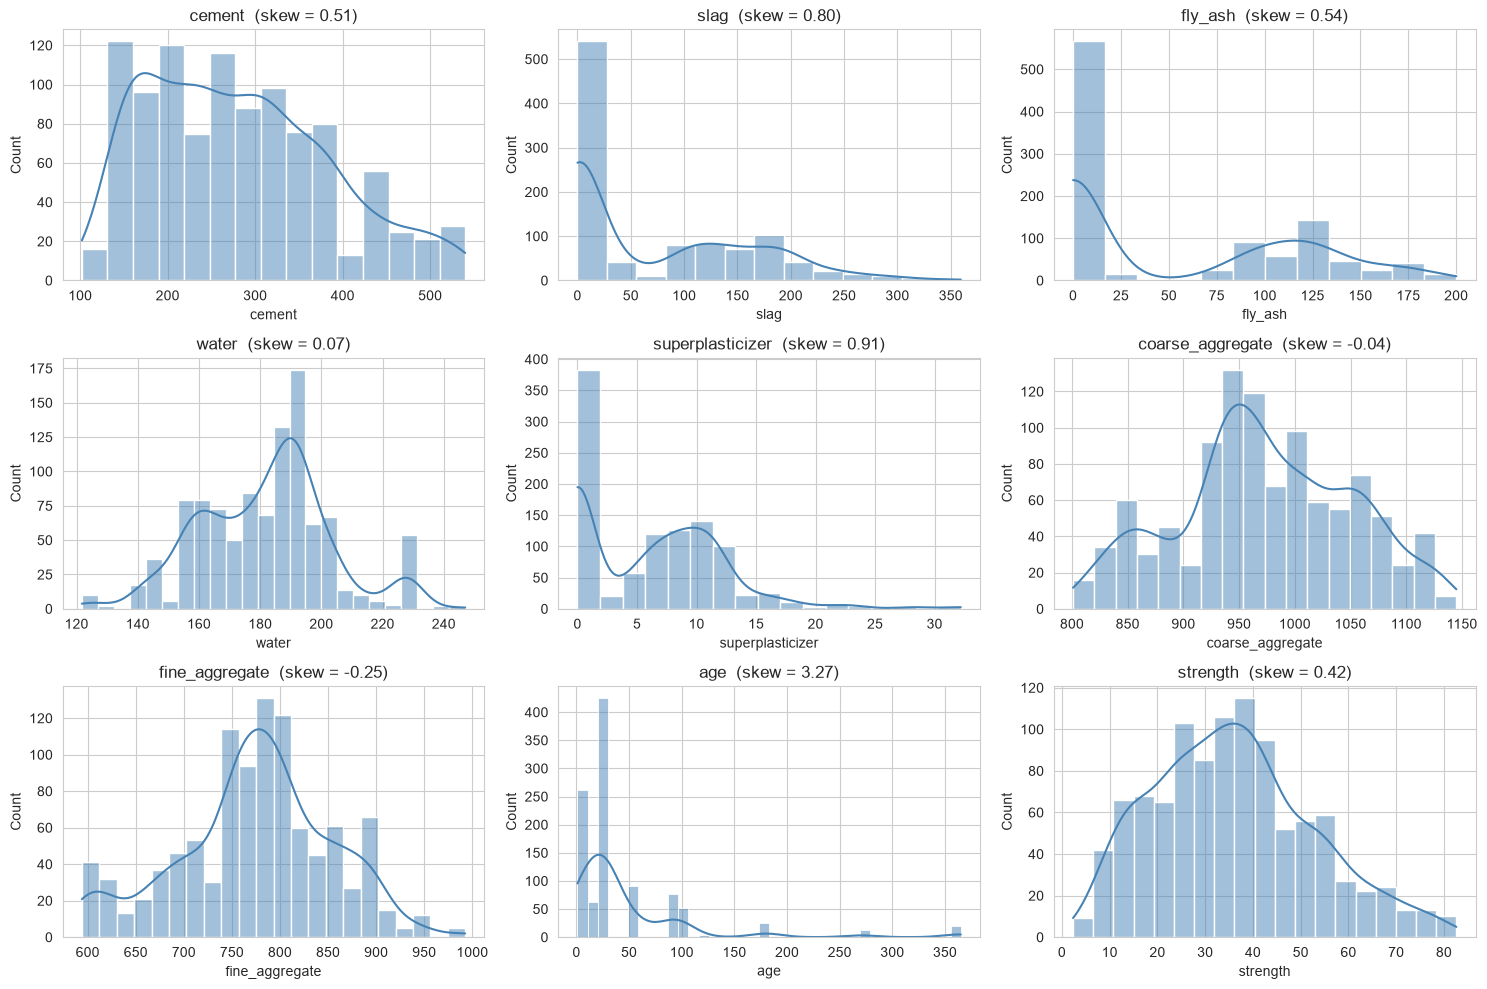

In [8]:
# Distribution of every column
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'{col}  (skew = {df[col].skew():.2f})')
plt.tight_layout(); plt.show()

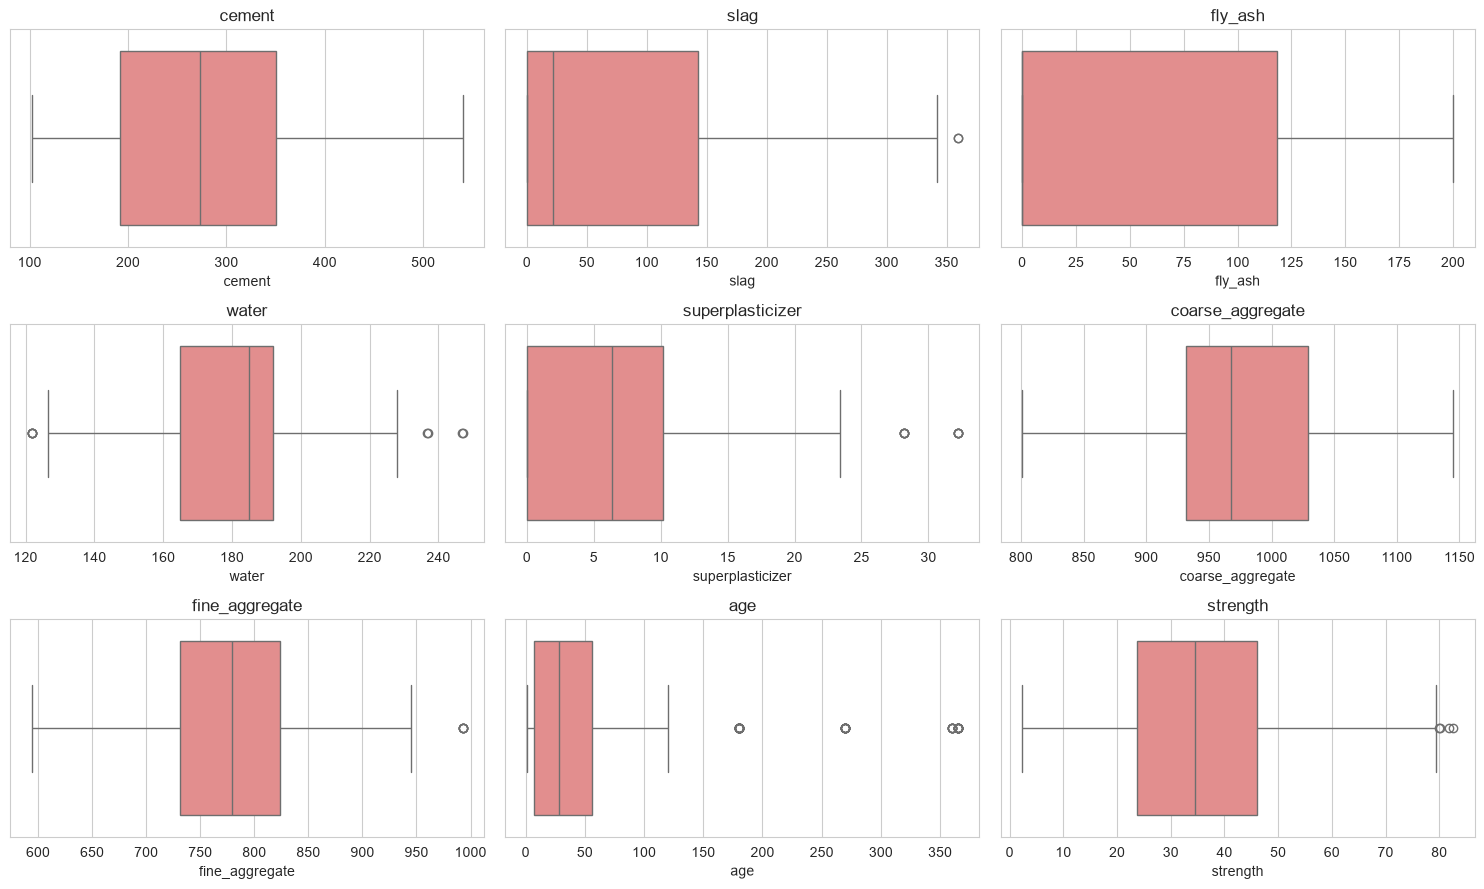

In [9]:
# Box plots of every column
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.ravel(), df.columns):
    sns.boxplot(x=df[col], ax=ax, color='lightcoral')
    ax.set_title(col)
plt.tight_layout(); plt.show()

# **DataCleaning**

## **Missing Values**

In [10]:
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_%': (df.isnull().sum() / len(df) * 100).round(3)
}).sort_values('missing_count', ascending=False)
missing

,missing_count,missing_%
cement,0,0.0
slag,0,0.0
fly_ash,0,0.0
water,0,0.0
superplasticizer,0,0.0
coarse_aggregate,0,0.0
fine_aggregate,0,0.0
age,0,0.0
strength,0,0.0


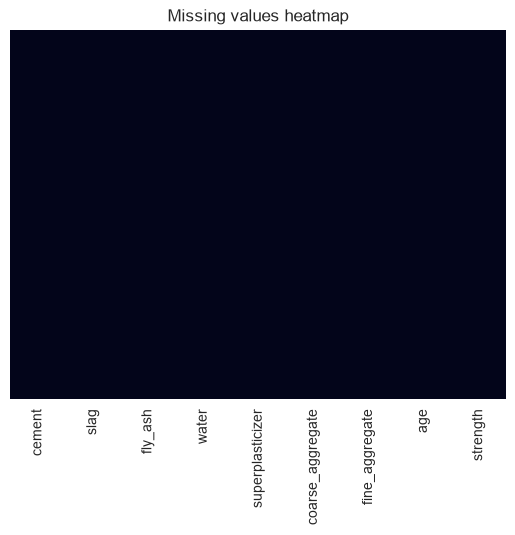

In [11]:
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing values heatmap')
plt.show()

**Hidden missing values?**

No real nulls, but zeros can also hide missing data. Check which columns contain zeros.

In [12]:
zeros = (df == 0).sum().to_frame('zero_count')
zeros['zero_%'] = (zeros['zero_count'] / len(df) * 100).round(2)
zeros[zeros['zero_count'] > 0]

,zero_count,zero_%
slag,466,45.24
fly_ash,566,54.95
superplasticizer,379,36.80


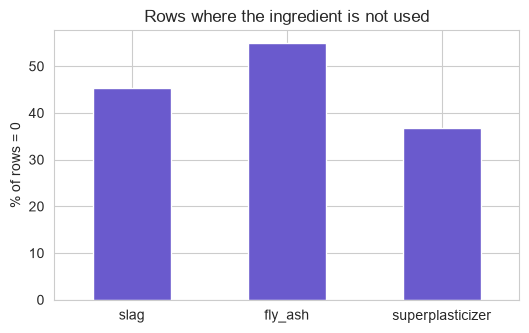

In [13]:
zero_cols = ['slag', 'fly_ash', 'superplasticizer']
(df[zero_cols] == 0).mean().mul(100).plot(kind='bar', color='slateblue', figsize=(6, 3.5))
plt.ylabel('% of rows = 0'); plt.title('Rows where the ingredient is not used'); plt.xticks(rotation=0)
plt.show()

**Decision:** zeros in `slag`, `fly_ash` and `superplasticizer` are **valid** - they mean that ingredient was simply not added to the mix. They are **not** missing values, so they are kept as 0.

## **Data Inconsistency**

### **1. Invalid / impossible values**

In [14]:
invalid = pd.Series({
    'negative values (any column)'       : (df < 0).sum().sum(),
    'cement <= 0'                        : (df['cement'] <= 0).sum(),
    'water <= 0'                         : (df['water'] <= 0).sum(),
    'coarse_aggregate <= 0'              : (df['coarse_aggregate'] <= 0).sum(),
    'fine_aggregate <= 0'                : (df['fine_aggregate'] <= 0).sum(),
    'age <= 0'                           : (df['age'] <= 0).sum(),
    'strength <= 0'                      : (df['strength'] <= 0).sum(),
    'total mix weight outside 2000-2700' : (~df[features[:-1]].sum(axis=1).between(2000, 2700)).sum(),
}, name='invalid_rows')
invalid

negative values (any column)          0
cement <= 0                           0
water <= 0                            0
coarse_aggregate <= 0                 0
fine_aggregate <= 0                   0
age <= 0                              0
strength <= 0                         0
total mix weight outside 2000-2700    0
Name: invalid_rows, dtype: int64

Total ingredient weight per m³ of concrete is physically about 2,200 - 2,600 kg, so it is a good sanity check for contradictory rows.

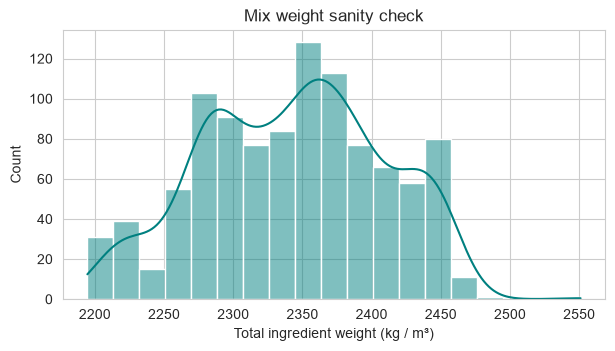

In [15]:
total = df[features[:-1]].sum(axis=1)
plt.figure(figsize=(7, 3.5))
sns.histplot(total, kde=True, color='teal')
plt.xlabel('Total ingredient weight (kg / m³)'); plt.title('Mix weight sanity check')
plt.show()

### **2. Duplicate rows**

In [16]:
n_dup = df.duplicated().sum()
print(f"Duplicate rows: {n_dup} ({n_dup/len(df)*100:.2f}%)")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Duplicate rows: 25 (2.43%)


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


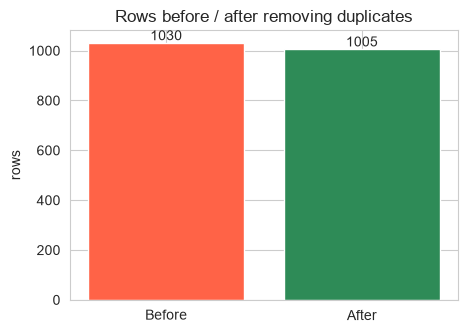

New shape: (1005, 9)


In [17]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)

plt.figure(figsize=(5, 3.5))
plt.bar(['Before', 'After'], [before, len(df)], color=['tomato', 'seagreen'])
for i, v in enumerate([before, len(df)]):
    plt.text(i, v, v, ha='center', va='bottom')
plt.title('Rows before / after removing duplicates'); plt.ylabel('rows')
plt.show()
print("New shape:", df.shape)

### **3. Datatypes**

In [18]:
df.dtypes

cement              float64
slag                float64
fly_ash             float64
water               float64
superplasticizer    float64
coarse_aggregate    float64
fine_aggregate      float64
age                   int64
strength            float64
dtype: object

All columns are already numeric (`float64` / `int64`), so no type conversion is needed. `age` is stored as integer days.

In [19]:
print("Unique age values (curing days):")
print(sorted(df['age'].unique()))

Unique age values (curing days):
[np.int64(1), np.int64(3), np.int64(7), np.int64(14), np.int64(28), np.int64(56), np.int64(90), np.int64(91), np.int64(100), np.int64(120), np.int64(180), np.int64(270), np.int64(360), np.int64(365)]


# **Outlier**

In [20]:
df[features].skew().rename('skewness')

cement              0.564997
slag                0.855246
fly_ash             0.497324
water               0.034119
superplasticizer    0.981572
coarse_aggregate   -0.065242
fine_aggregate     -0.252323
age                 3.253974
Name: skewness, dtype: float64

### **IQR Method**

In [21]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in df.columns:
    lo, hi = iqr_bounds(df[col])
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, round(lo, 2), round(hi, 2), n, round(n / len(df) * 100, 2)])
pd.DataFrame(rows, columns=['column', 'lower_bound', 'upper_bound', 'n_outliers', '% outliers'])

,column,lower_bound,upper_bound,n_outliers,% outliers
0,cement,-46.80,586.48,0,0.00
1,slag,-213.75,356.25,2,0.20
2,fly_ash,-177.40,295.68,0,0.00
3,water,127.12,232.43,15,1.49
4,superplasticizer,-15.00,25.00,10,1.00
5,coarse_aggregate,783.50,1179.50,0,0.00
6,fine_aggregate,577.45,969.05,5,0.50
7,age,-66.50,129.50,59,5.87
8,strength,-8.49,76.89,8,0.80


### **Z-Score Method**

In [22]:
from scipy import stats
pd.DataFrame({
    'column': df.columns,
    'n_outliers (|z|>3)': [(np.abs(stats.zscore(df[c])) > 3).sum() for c in df.columns]
})

,column,n_outliers (|z|>3)
0,cement,0
1,slag,4
2,fly_ash,0
3,water,2
4,superplasticizer,10
5,coarse_aggregate,0
6,fine_aggregate,0
7,age,33
8,strength,0


### **Handle Outliers**

| Column | Decision | Reason |
|---|---|---|
| `water`, `superplasticizer`, `fine_aggregate`, `slag` | **Cap** at IQR bounds | a small number of extreme amounts; capping keeps the row but limits their pull |
| `age` | **Keep values, log-transform** (next section) | 7, 28, 90, 365 days are real curing times; capping would destroy valid information |
| `cement`, `fly_ash`, `coarse_aggregate` | Keep | no outliers |
| `strength` (target) | Keep | high values are genuine high-strength mixes; the target must not be altered |

In [23]:
cap_cols = ['slag', 'water', 'superplasticizer', 'fine_aggregate']
df_before_cap = df[cap_cols].copy()

for c in cap_cols:
    lo, hi = iqr_bounds(df[c])
    lo = max(lo, 0)                                   # amounts can not be negative
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    df[c] = df[c].clip(lo, hi)
    print(f"{c:18s} capped {n:3d} values -> [{lo:.1f}, {hi:.1f}]")

slag               capped   2 values -> [0.0, 356.2]
water              capped  15 values -> [127.1, 232.4]
superplasticizer   capped  10 values -> [0.0, 25.0]
fine_aggregate     capped   5 values -> [577.4, 969.1]


### **Visualization – before vs after capping**

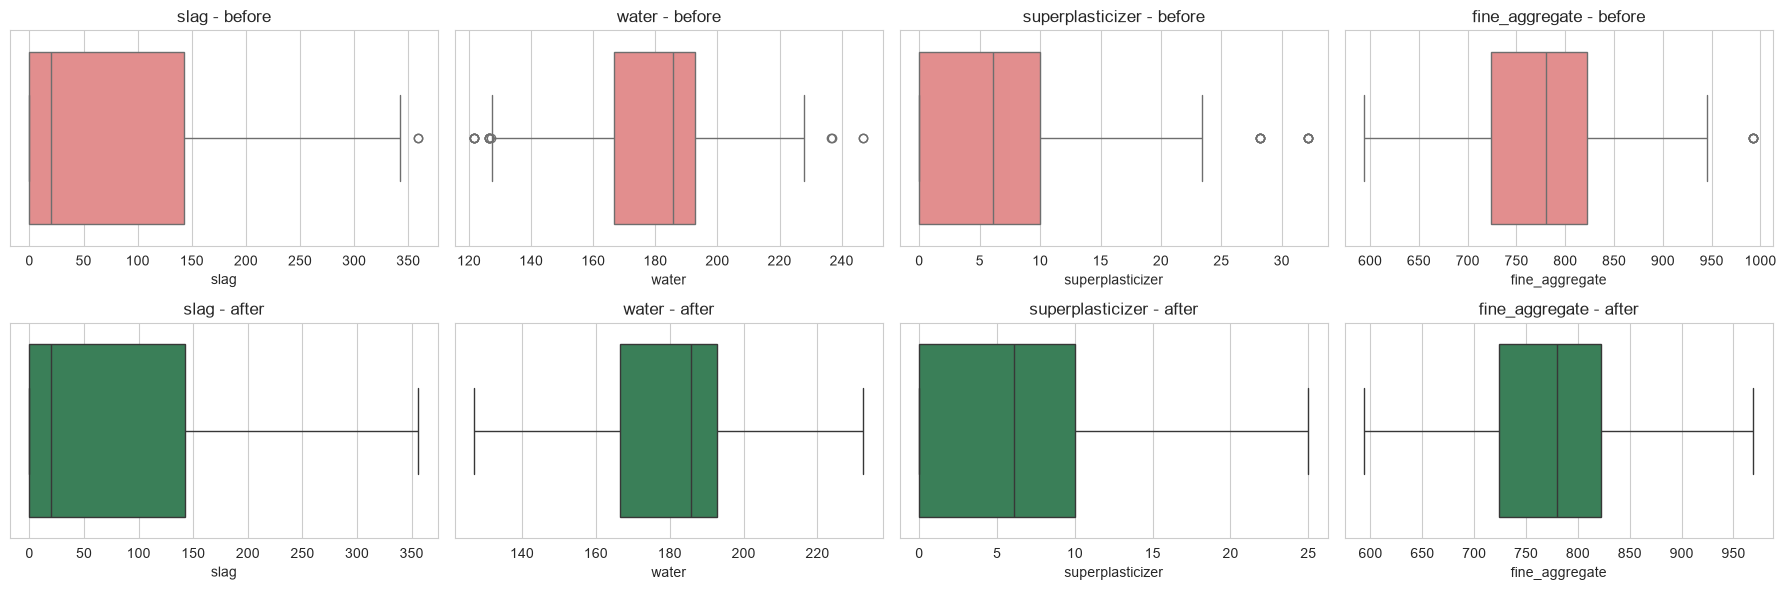

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for i, c in enumerate(cap_cols):
    sns.boxplot(x=df_before_cap[c], ax=axes[0, i], color='lightcoral'); axes[0, i].set_title(f'{c} - before')
    sns.boxplot(x=df[c],            ax=axes[1, i], color='seagreen');   axes[1, i].set_title(f'{c} - after')
plt.tight_layout(); plt.show()

# **Skewness – Log Transform of `age`**

`age` is strongly right-skewed (most samples are 28 days or younger, a few go up to 365). `log1p` (= log(1 + x)) pulls in the long tail without touching the order of the values.

In [25]:
age_before = df['age'].copy()
print("Skewness before:", round(age_before.skew(), 3))

df['age'] = np.log1p(df['age'])
print("Skewness after :", round(df['age'].skew(), 3))

Skewness before: 3.254
Skewness after : 0.006


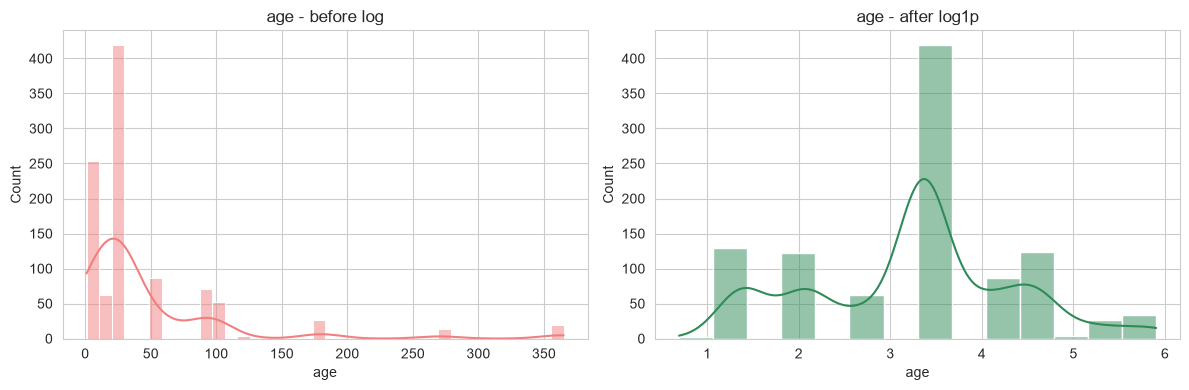

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(age_before, kde=True, ax=axes[0], color='lightcoral'); axes[0].set_title('age - before log')
sns.histplot(df['age'],  kde=True, ax=axes[1], color='seagreen');   axes[1].set_title('age - after log1p')
plt.tight_layout(); plt.show()

# **Scalization – Standard Scaler**

The features are on very different scales (coarse aggregate ~ 1000 kg, superplasticizer ~ 0 - 25 kg). Standardizing puts every feature at mean 0 and standard deviation 1, which Linear / Ridge / Lasso, SVR, KNN and Neural Networks need. The **target `strength` is not scaled**, so it stays in MPa.

In [27]:
from sklearn.preprocessing import StandardScaler

df_before_scale = df.copy()

scaler = StandardScaler()
df[features] = scaler.fit_transform(df[features])

df[features].agg(['mean', 'std']).round(3)

,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age
mean,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


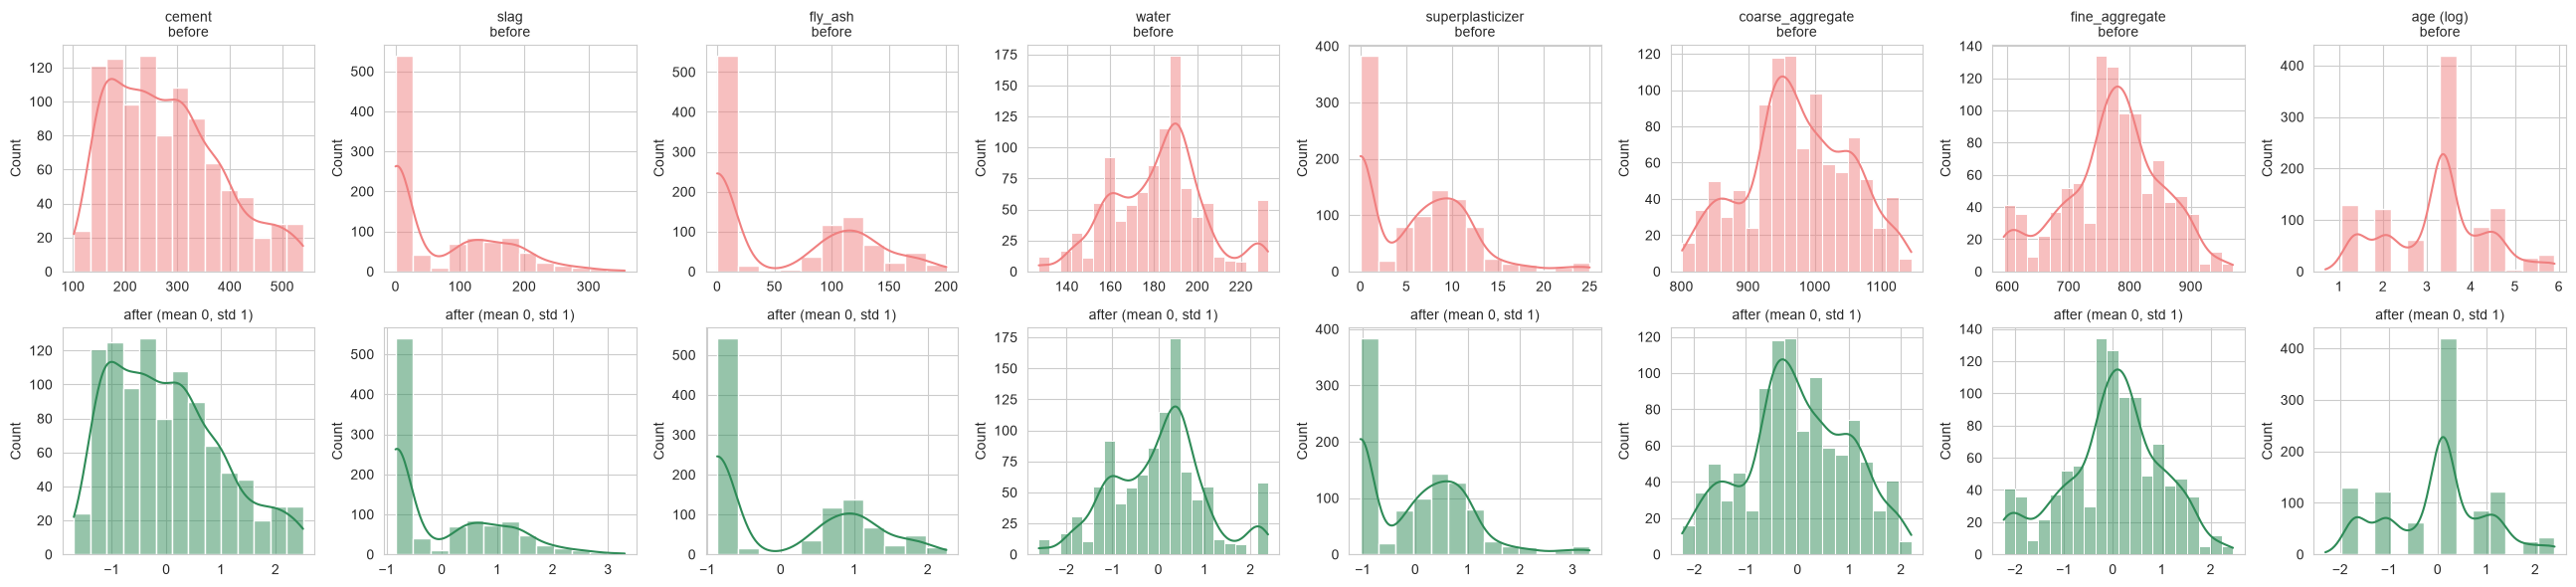

In [28]:
fig, axes = plt.subplots(2, 8, figsize=(26, 6))
for i, c in enumerate(features):
    sns.histplot(df_before_scale[c], kde=True, ax=axes[0, i], color='lightcoral')
    axes[0, i].set_title(c + (' (log)' if c == 'age' else '') + '\nbefore', fontsize=10)
    sns.histplot(df[c], kde=True, ax=axes[1, i], color='seagreen')
    axes[1, i].set_title('after (mean 0, std 1)', fontsize=10)
    axes[0, i].set_xlabel(''); axes[1, i].set_xlabel('')
plt.tight_layout(); plt.show()

# **Final Data Visualization**

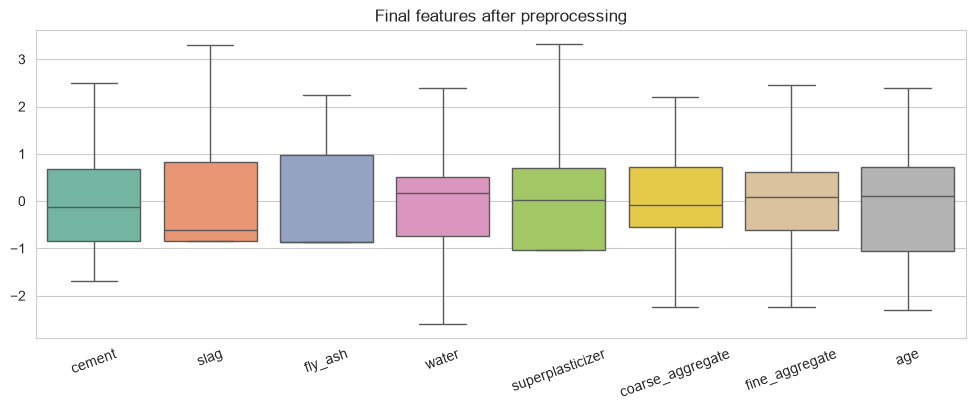

In [29]:
# Box plots of the final features (all on the same scale now)
plt.figure(figsize=(12, 4))
sns.boxplot(data=df[features], palette='Set2')
plt.title('Final features after preprocessing'); plt.xticks(rotation=20)
plt.show()

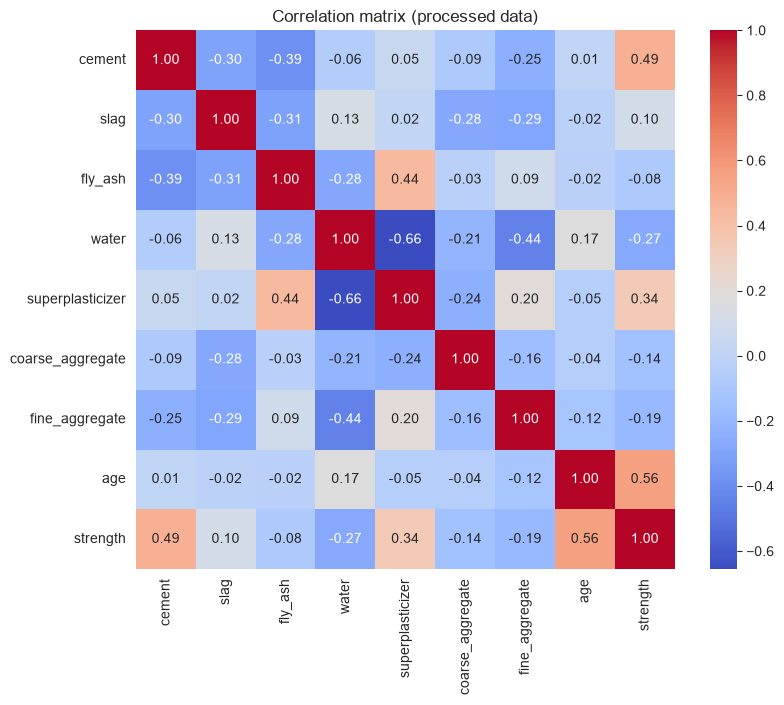

In [30]:
# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation matrix (processed data)')
plt.show()

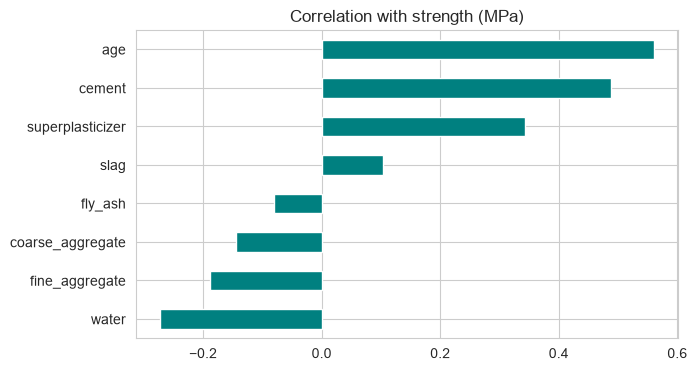

In [31]:
# Correlation of every feature with strength
df.corr()['strength'].drop('strength').sort_values().plot(kind='barh', color='teal', figsize=(7, 4))
plt.title('Correlation with strength (MPa)')
plt.show()

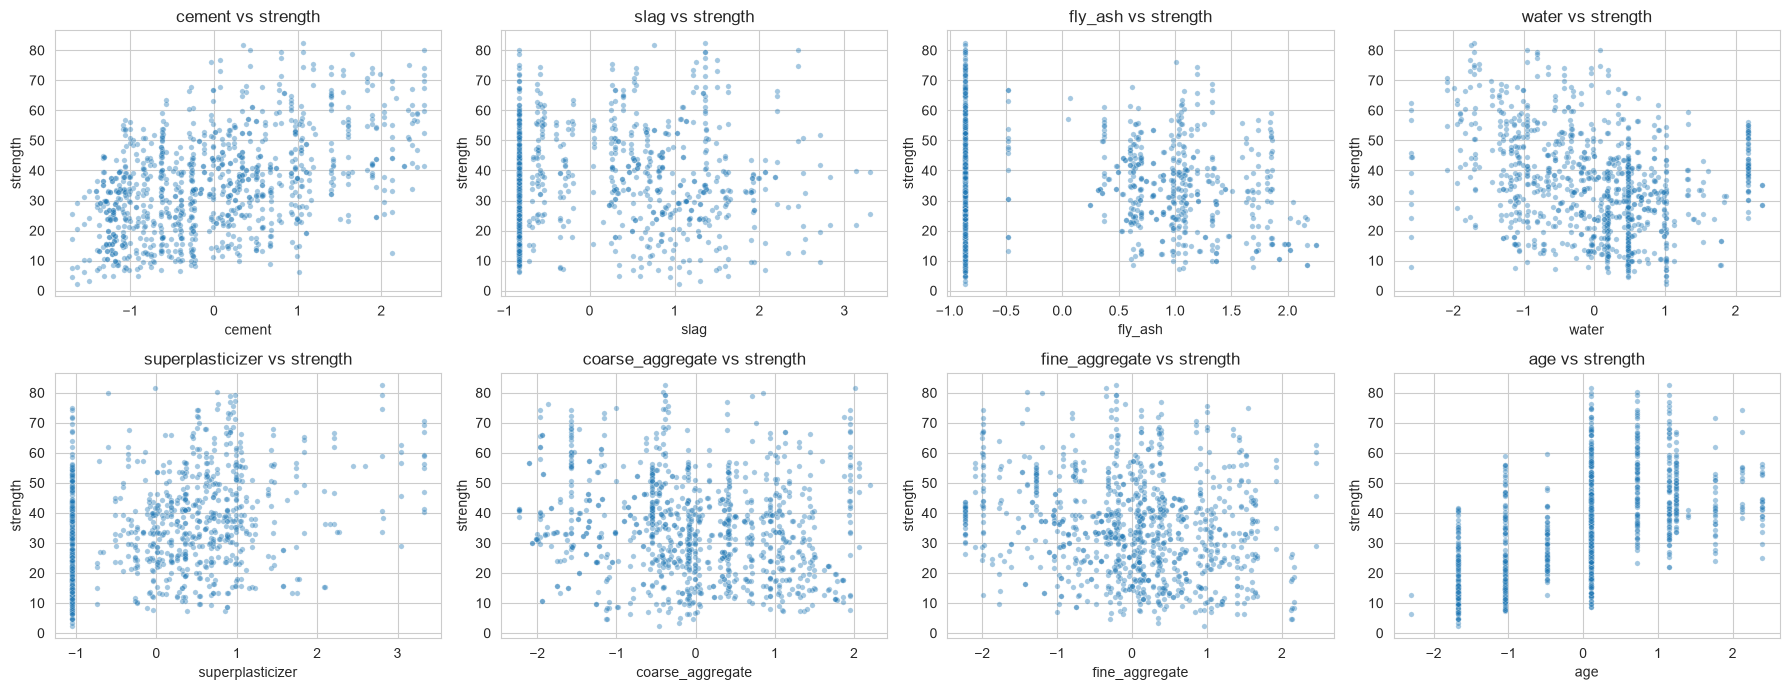

In [32]:
# Feature vs target
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), features):
    sns.scatterplot(x=df[c], y=df['strength'], ax=ax, alpha=0.4, s=15)
    ax.set_title(f'{c} vs strength')
plt.tight_layout(); plt.show()

# **Before vs After Preprocessing**

In [33]:
summary = pd.DataFrame({
    'Before preprocessing': [df_raw.shape[0], df_raw.shape[1], int(df_raw.isnull().sum().sum()),
                             int(df_raw.duplicated().sum()), round(df_raw.iloc[:, 7].skew(), 2)],
    'After preprocessing' : [df.shape[0], df.shape[1], int(df.isnull().sum().sum()),
                             int(df.duplicated().sum()), round(df['age'].skew(), 2)],
}, index=['Rows', 'Columns', 'Null values', 'Duplicate rows', 'Skewness of age'], dtype=object)
summary

,Before preprocessing,After preprocessing
Rows,1030,1005
Columns,9,9
Null values,0,0
Duplicate rows,25,0
Skewness of age,3.27,0.01


In [34]:
print("BEFORE (raw data):")
display(df_raw.head())
print("\nAFTER (preprocessed data):")
display(df.head())

BEFORE (raw data):


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



AFTER (preprocessed data):


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,2.506120,-0.836598,-0.865363,-0.948723,-0.608250,0.846308,-1.207186,0.110360,79.986111
1,2.506120,-0.836598,-0.865363,-0.948723,-0.608250,1.039755,-1.207186,0.110360,61.887366
2,0.516534,0.818322,-0.865363,2.171753,-1.045223,-0.546505,-2.232243,2.126623,40.269535
3,0.516534,0.818322,-0.865363,2.171753,-1.045223,-0.546505,-2.232243,2.397748,41.052780
4,-0.767348,0.701026,-0.865363,0.469675,-1.045223,0.051889,0.661669,2.385338,44.296075


# **Save & Download Both Files (CSV)**

- `concrete_before_preprocessing.csv` -> raw data exactly as in the Excel file
- `concrete_after_preprocessing.csv` -> cleaned, capped, log-transformed and scaled data

In [35]:
before_csv = 'concrete_before_preprocessing.csv'
after_csv  = 'concrete_after_preprocessing.csv'

df_raw.to_csv(before_csv, index=False)
df.to_csv(after_csv, index=False)

print("Saved:", os.path.abspath(before_csv), df_raw.shape)
print("Saved:", os.path.abspath(after_csv),  df.shape)

Saved: c:\Users\adnan\Desktop\Regression\Concrete_Dataset\concrete_before_preprocessing.csv (1030, 9)
Saved: c:\Users\adnan\Desktop\Regression\Concrete_Dataset\concrete_after_preprocessing.csv (1005, 9)


In [36]:
# Download both files
try:
    from google.colab import files
    files.download(before_csv)
    files.download(after_csv)
except ImportError:
    print("Not running in Colab - both files are saved in:", os.getcwd())

Not running in Colab - both files are saved in: c:\Users\adnan\Desktop\Regression\Concrete_Dataset


# Next

Split the preprocessed data into train / test and build regression models (Linear Regression, Random Forest, XGBoost). Evaluate with **R², RMSE and MAE**.